# The Sellar problem under the MDO architectures of Martins & Lambe

Martins & Lambe (2013) survey the architectures that solve a multidisciplinary design optimisation (MDO) problem: the monolithic AAO, SAND, IDF and MDF, and the distributed ones derived from IDF or MDF, such as collaborative optimisation and analytical target cascading. Each is presented there as its own problem formulation with its own XDSM. This notebook shows that, in cottax, those that solve the original problem exactly are each the same declared problem with a different sequence of graph operations applied to it.

The problem is Sellar, declared once as a computation graph. An architecture is a *plan*: a function in `distributed_architectures.py` that takes that declared graph and applies cottax's operations to it. These operations cut couplings into copies, change which variables an optimiser owns, insert subproblems and the functions they need, and nest one problem inside another. cottax refuses any operation whose result is not a valid graph, so each plan is a valid graph at every step, and its final graph is proved executable before it runs.

For each architecture the notebook then:

1. draws the resulting graph as an XDSM, to compare with Martins & Lambe's figure;
2. assigns solvers to its problems and runs it from the standard starting point;
3. compares the answer with the known optimum of Sellar.

Three architectures of the survey are not built here: CSSO, BLISS and ECO. Each works through approximations of the disciplines (surrogates, linearisations or quadratic models) refreshed between iterations, rather than through a fixed reformulation of the problem. An overview of all outcomes closes the notebook.

## The problem

Sellar, Batill & Renaud (1996) couple two disciplines through their outputs $y_1$ and $y_2$:

$$D_1:\; y_1 = z_1^2 + z_2 + x_1 - 0.2\,y_2, \qquad D_2:\; y_2 = \sqrt{|y_1|} + z_1 + z_2 .$$

The design problem is

$$\min_{z_1, z_2, x_1}\; f = x_1^2 + z_2 + y_1 + e^{-y_2} \quad \text{subject to}\quad g_1 = 1 - \frac{y_1}{3.16} \le 0, \qquad g_2 = \frac{y_2}{24} - 1 \le 0,$$

with $-10 \le z_1 \le 10$, $0 \le z_2 \le 10$ and $0 \le x_1 \le 10$. These are the bounds of Gray et al. (2013) and GEMSEO; OpenMDAO's tutorial narrows $z_1$ to $[0, 10]$. $D_2$ uses $\sqrt{|y_1|}$, as GEMSEO and OpenMDAO write it, so that it is defined for any value an optimiser may try.

The optimum is $f = 3.18339$ at $z = (1.97764,\, 0)$, $x_1 = 0$, with $y = (3.16,\, 3.75528)$. At this point $g_1$ is active, and so are the lower bounds on $z_2$ and $x_1$: although written as bounds, they act as constraints at the solution. Sellar also has a second local minimum, $f = 4.131$ at $z = (-1.717,\, 0.138)$, which matters for ASO below. Every plan starts from the point Gray et al. use: $z = (5, 2)$, $x_1 = 1$, and $y = (1, 1)$ for any coupling an optimiser owns.

## The declared problem

The problem is declared once, in the form of Martins & Lambe's Eq. 1, and nothing in the declaration chooses an architecture:

- the two disciplines $D_1$ and $D_2$, as functions;
- the objective split into its discipline terms, $f_1 = x_1^2 + y_1$ (computed by $F_1$) and $f_2 = z_2 + e^{-y_2}$ (by $F_2$), and their sum $f$ (by $F$);
- each design constraint ($G_1$, $G_2$) and the bounds of each design variable as separate requirements, so that an architecture can place each with the problem that owns its variables;
- one optimiser, $\mathrm{Opt}$, minimising $f$ over $z_1$, $z_2$ and $x_1$.

Splitting the objective into terms costs nothing for the architectures that take it whole, and it is what penalty decomposition and quasi-separable decomposition need.

Martins & Lambe's problem statement has no bounds. Here a variable's bounds go with whichever problem owns the variable. In a distributed architecture the system subproblem therefore holds the bounds of $z$, and the subproblem of discipline 1 those of $x_1$. A subproblem's own copies of $z$ are unbounded; they equal $z$ once the architecture converges. Read this way, Sellar has no shared constraints $c_0$: its two constraints each belong to one discipline.

The XDSM below draws this declared graph as written. The optimiser $\mathrm{Opt}$ is drawn tinted, because no solver has been assigned to it yet. The requirements are drawn as hollow hexagons, because they determine nothing. Each is labelled by the relation it holds: $g_1 \le 0$ and $g_2 \le 0$ for the design constraints, and one per design variable for its bounds. The graph is not yet executable: the coupling between $D_1$ and $D_2$ is a cycle that no problem resolves, and no problem holds the requirements. Every architecture below is a way of making it executable.

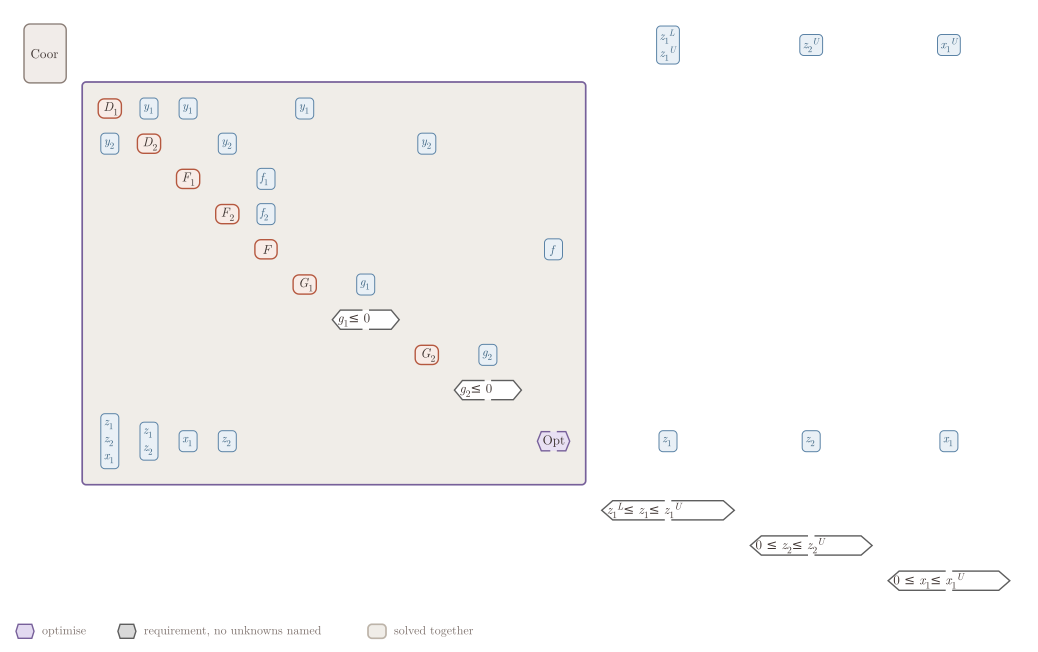

In [1]:
import jax
jax.config.update('jax_enable_x64', True)
from IPython.display import SVG, Markdown, display

from sellar_helpers import compare, declared_xdsm, failure, overview, sellar
from distributed_architectures import RUNS

results = {}
def solve(name, model):
    """Run `model` as `RUNS[name]` sets out, print its error against the optimum, keep the outcome."""
    how = RUNS[name]
    try:
        answer = how.answer(model)
    except Exception as error:
        results[name] = (None, failure(error), how.note)
        print('failed:', failure(error))
        return
    results[name] = (answer, how.tol, how.note)
    print(compare(answer, how.tol))

base = sellar()
display(SVG(declared_xdsm(base)))

## Notation and how to read the drawings

The names follow Martins & Lambe where they have one.

| name | meaning |
|---|---|
| $z_1, z_2$ | shared design variables, Martins & Lambe's $x_0$ |
| $x_1$ | the local design variable of $D_1$; $D_2$ has none |
| $y_1, y_2$ | coupling variables, the outputs of the disciplines |
| $f$, $f_1$, $f_2$ | the objective and its discipline terms |
| $g_1$, $g_2$ | the design constraints, each $\le 0$; Martins & Lambe write $c_i \ge 0$, so $c_i = -g_i$ |
| $\hat y_i$ | a copy (target) of $y_i$, owned by an optimiser or an MDA |
| $\hat z_k^{(i)}$ | subproblem $i$'s own copy of $z_k$, Martins & Lambe's $\hat x_{0i}$ |
| $v^{(0)}$ | the starting value of $v$ |
| $v^L$, $v^U$ | the lower and upper bound of $v$ |
| $\mathrm{Opt}$ | the declared optimiser, which becomes the system subproblem in a distributed architecture |
| $\mathrm{Opt}_i$ | the subproblem of discipline $i$ |
| $\mathrm{FP}$ | a fixed-point iteration: the multidisciplinary analysis (MDA) of MDF and ASO, or ATC's iteration over its subproblems |

The variables a particular architecture adds are defined in its section.

The XDSMs read as Martins & Lambe's, with these differences:

- There are no process numbers. The diagonal is in run order, and a shaded ring encloses everything one problem iterates, so the nesting of the rings shows which problem is solved inside which.
- Coor supplies every value that nothing in the graph computes: the starting values of all optimisers and fixed points, and the non-zero bound values, which Martins & Lambe leave out. These all share Coor's one row, each in the column of the node that reads it.
- In the architectures every requirement has been placed with a problem, so a problem lists what it holds in slots under its name: $\min$ for its objective, $\le 0$ or $= 0$ for a constraint, or the relation itself.
- Each function of the declared problem keeps its own block ($F_1$, $G_1$, ...), where Martins & Lambe draw one block for a discipline's functions.
- There is no column of final values ($x^*$, $y^*$) leaving the drawing, and the outer loop that updates a penalty weight is not drawn: it runs in the notebook (see IPD).

### How each plan is run

Every optimiser is solved with SLSQP, every fixed point with Picard iteration and every root-finding problem with Newton's method. Wherever an optimiser's functions depend on the solution of a nested constrained subproblem, it needs the derivative of that solution, and cottax does not yet differentiate through SLSQP. Such a system subproblem therefore uses forward finite differences, so a distributed architecture is typically compared with the optimum within a tolerance of $10^{-3}$ rather than $10^{-4}$. Where an architecture needed a further setting to converge, its section says so.

## Monolithic architectures

The monolithic architectures keep a single optimiser. SAND, IDF and MDF are cottax's presets applied to the declared optimiser $\mathrm{Opt}$; AAO is written out.

A preset takes a *cut rule*, which decides which couplings are cut into copies. Its default, Gauss–Seidel, cuts only what breaks the coupling cycle: here $y_2$, so $D_1$ reads a copy $\hat y_2$ while $y_1$ flows forward from $D_1$ to $D_2$. That leaves the optimiser one variable and one constraint fewer. Martins & Lambe's IDF copies every coupling and analyses the disciplines in parallel, which is the Jacobi rule, so SAND and IDF are built with it here. MDF keeps the default: the rule only changes the order in which its MDA updates the couplings.

### AAO (Martins & Lambe Eq. 1, Fig. 4)

In the all-at-once formulation the optimiser owns every variable at once: the design variables, copies of the couplings, the couplings themselves and the state variables. It holds both the consistency between each copy and its coupling, and every discipline's residual.

Sellar's disciplines have no states, so a discipline's residual is the difference between the coupling the optimiser chose and what the discipline computes from the copies, $y_i - Y_i = 0$. The plan renames each discipline's output to $Y_i$, lets the optimiser own $y_i$ and $\hat y_i$, and gives it both sets of equalities.

**Variables it adds.** $\hat y_1$ and $\hat y_2$, the optimiser\'s copies of the couplings; $Y_1$ and $Y_2$, what the disciplines compute for the couplings, now that the optimiser owns $y_1$ and $y_2$.

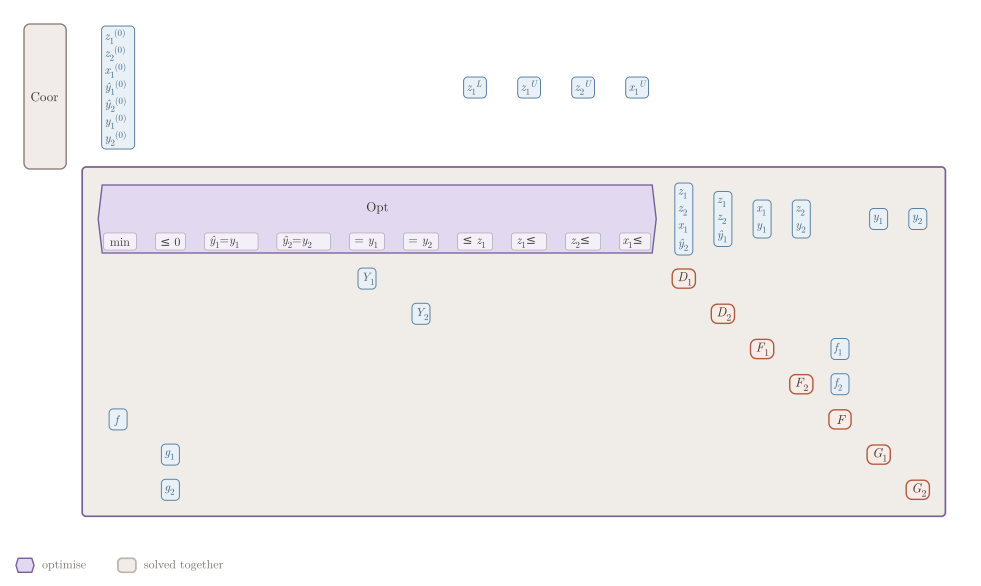

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       4.0e-06   -1.1e-06    0.0e+00    2.8e-16   -4.4e-16   -2.2e-06
within 0.0001


In [2]:
from distributed_architectures import aao
model = aao(base)
display(SVG(RUNS['AAO'].xdsm(model)))
solve('AAO', model)

### SAND (Martins & Lambe Eq. 2, Fig. 5)

Simultaneous analysis and design removes the copies from AAO: the optimiser owns the design variables, the couplings and the states, and holds the residuals, so no analysis is ever converged on its own.

For Sellar's explicit disciplines this is IDF's graph under another name. SAND's optimiser owns $y_i$ and holds $y_i = Y_i$; cottax's SAND lets each discipline keep its output $y_i$, and the optimiser owns a copy $\hat y_i$ and holds $\hat y_i = y_i$. The two differ only for a discipline with states, which cottax's SAND makes the optimiser's.

**Variables it adds.** $\hat y_1$ and $\hat y_2$, as in IDF.

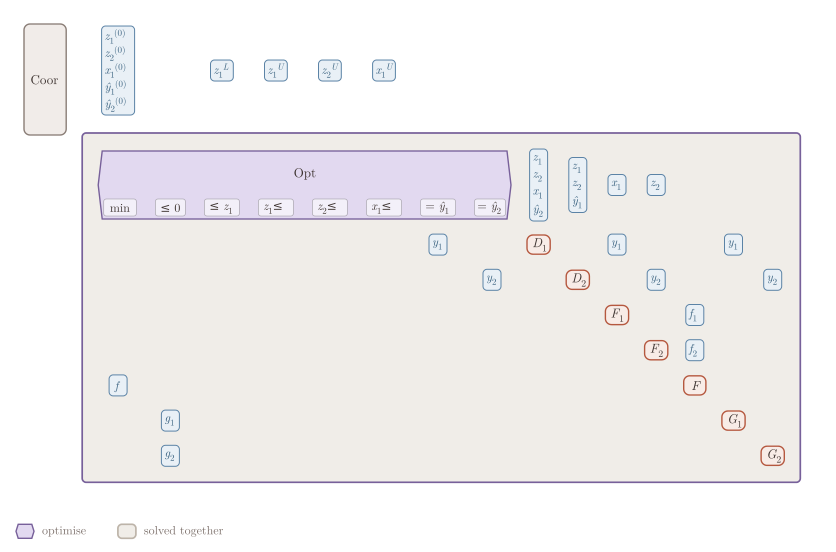

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       4.0e-06   -1.1e-06    0.0e+00    1.8e-16    9.2e-11   -2.2e-06
within 0.0001


In [3]:
from distributed_architectures import sand
model = sand(base)
display(SVG(RUNS['SAND'].xdsm(model)))
solve('SAND', model)

### IDF (Martins & Lambe Eq. 3, Fig. 6)

Individual discipline feasible removes the couplings and states from AAO: the optimiser owns the design variables and copies of the couplings, and holds the consistency between each copy and the coupling it stands for. Each discipline is analysed on its own, from the copies.

**Variables it adds.** $\hat y_1$ and $\hat y_2$, the optimiser\'s copies of the couplings.

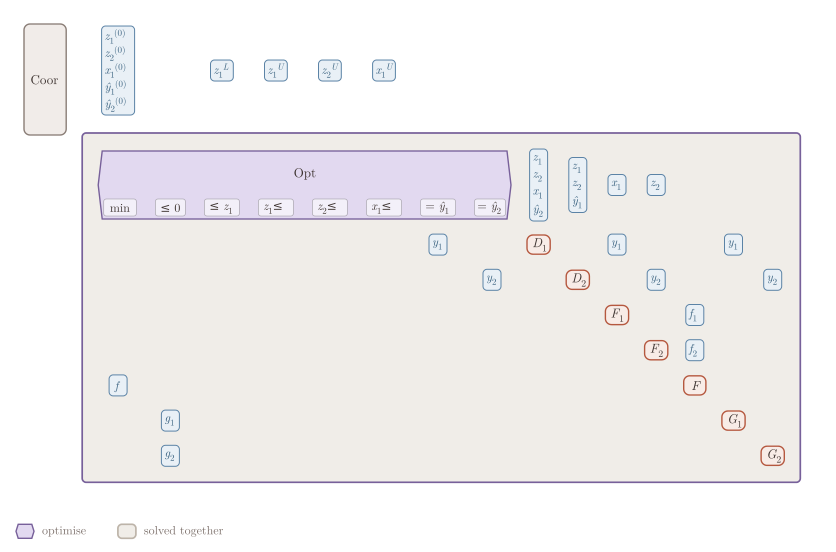

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       4.0e-06   -1.1e-06    0.0e+00    1.8e-16    9.2e-11   -2.2e-06
within 0.0001


In [4]:
from distributed_architectures import idf
model = idf(base)
display(SVG(RUNS['IDF'].xdsm(model)))
solve('IDF', model)

### MDF (Martins & Lambe Eq. 4, Fig. 7)

Multidisciplinary feasible removes both: the optimiser owns only the design variables. At every design point a multidisciplinary analysis converges the coupled disciplines, so every point the optimiser sees is consistent.

The MDA is a fixed point over the copy $\hat y_2$, solved by Picard iteration and nested inside the optimiser.

**Variables it adds.** $\hat y_2$, the copy of $y_2$ that the MDA iterates on.

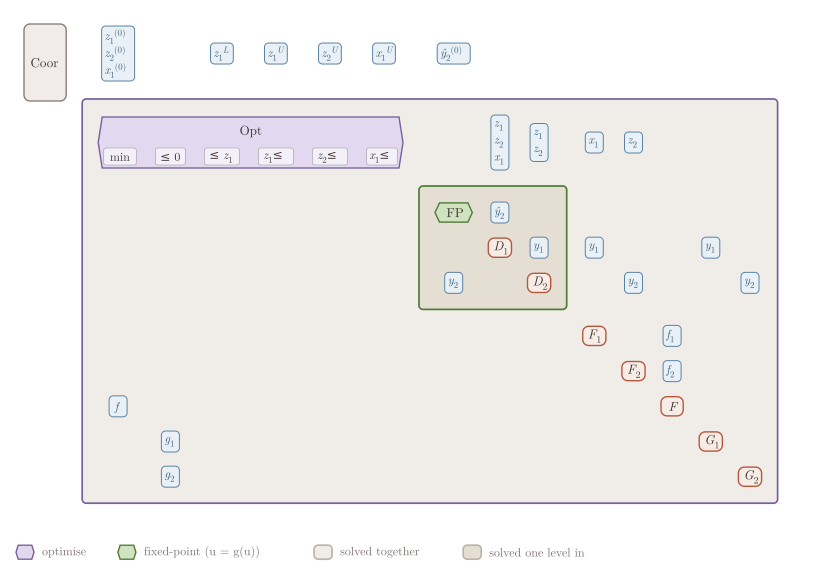

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       4.0e-06   -1.1e-06    9.7e-16    3.7e-16    8.5e-11   -2.2e-06
within 0.0001


In [5]:
from distributed_architectures import mdf
model = mdf(base)
display(SVG(RUNS['MDF'].xdsm(model)))
solve('MDF', model)

## Distributed architectures

A distributed architecture splits the optimisation itself: subproblems own part of the design variables and are coordinated by a system subproblem. In cottax the declared optimiser $\mathrm{Opt}$ becomes the system subproblem. A plan changes which variables it owns and what it minimises, inserts the subproblems and the functions they need, and places each constraint with the problem that owns its variables. Each plan follows Martins & Lambe's equations and figure, and applies one graph operation at a time in three steps. First the declared graph is made acyclic: the couplings and shared variables are cut, and the declared optimiser gives up its unknowns. Then the new subproblems and functions are inserted, and each constraint is combined into the problem that will own its variables. Finally each problem is given its unknowns, innermost first, and the problems inside it are nested in it. `distributed_architectures.py` lists the operations of each plan.

Martins & Lambe classify a distributed architecture by the monolithic one it derives from. Distributed IDF architectures keep copies of the couplings and enforce consistency constraints, either through a hierarchy of problems (multilevel) or through penalties. Distributed MDF architectures enforce consistency with an MDA.

Sellar's second discipline has no local design variable, so in several architectures its subproblem would have nothing of its own to optimise. Each section explains how that is handled.

## Distributed IDF: multilevel

### CO1 (Martins & Lambe Eqs. 9–10, Fig. 9)

In collaborative optimisation the system subproblem chooses the shared design variables and targets for the couplings, and minimises the objective at those targets. Each subproblem owns its own copy of the shared variables and its local variables, and minimises its inconsistency with the system subproblem's targets subject to its own constraints. In CO1 the system subproblem holds each consistency as a separate equality constraint.

For Sellar, the objective is evaluated at the system subproblem from its copies. Because $x_1$ appears in the objective, the system subproblem holds its own copy $\hat x_1$. It then has seven equality constraints and only five unknowns ($z_1$, $z_2$, $\hat x_1$, $\hat y_1$, $\hat y_2$), and SLSQP rejects the problem. Martins & Lambe warn of exactly this ("the system problem in CO1 has more equality constraints than variables"), and the plan is left as the method states it.

**Variables it adds.** $\hat z_k^{(i)}$, subproblem $i$\'s copy of $z_k$; $\hat x_1$ and $\hat y_i$, the system subproblem\'s copies of $x_1$ and of the couplings; $J_i$, the squared inconsistency of subproblem $i$ with the system subproblem, computed by the function node $J_i$.

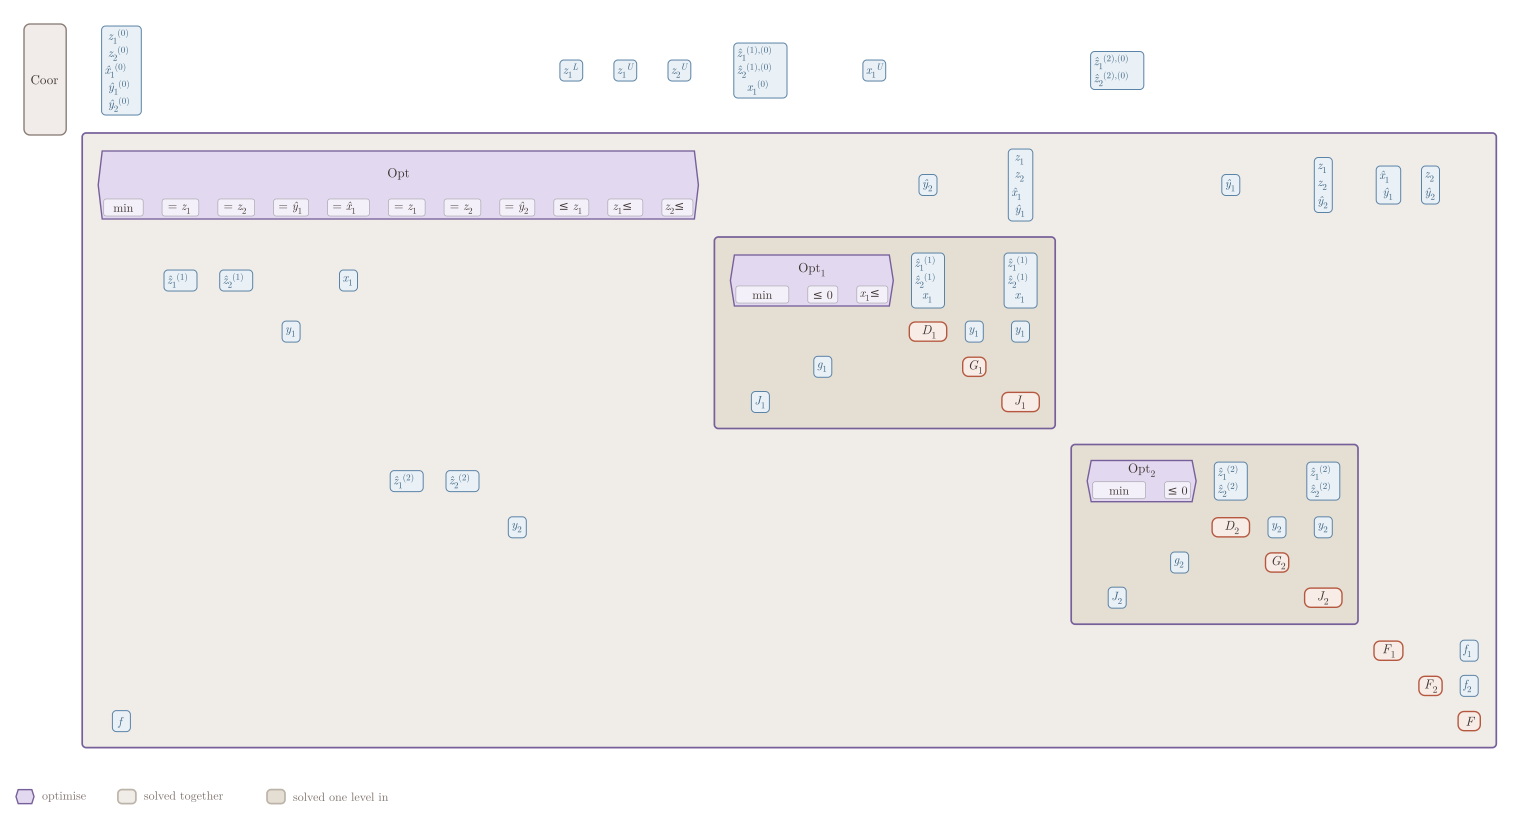

failed: SLSQP did not converge: More equality constraints than independent variables


In [6]:
from distributed_architectures import co
model = co(base, version=1)
display(SVG(RUNS['CO1'].xdsm(model)))
solve('CO1', model)

### CO2 (Martins & Lambe Eqs. 9–10, Fig. 9)

CO2 differs from CO1 only in the system subproblem, which holds a single constraint per subproblem: that its optimal inconsistency $J_i^*$ be zero.

Martins & Lambe note that the gradients of these constraints vanish at the optimum, which slows the system subproblem's convergence. In practice it holds $J_i^*$ to about $10^{-6}$. Because $J_1^*$ contains $(\hat x_1 - x_1)^2$, this leaves $x_1$ off by about the square root of that, roughly $10^{-3}$, so CO2 is compared within $2 \times 10^{-3}$. The reported $f$ is computed at the system subproblem's copies, and $x_1$ and $y$ are the subproblems' values.

**Variables it adds.** The same as CO1.

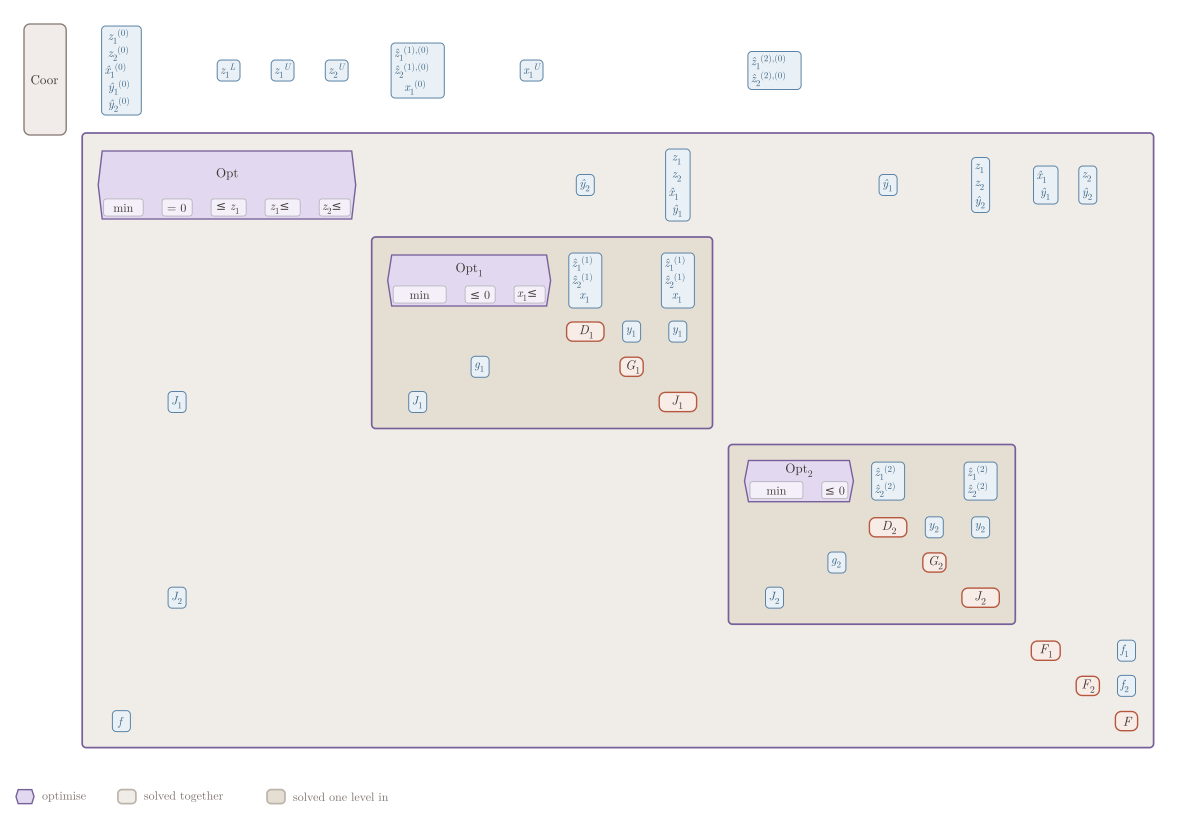

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       5.7e-06   -2.7e-04    2.5e-16    1.0e-03    1.4e-08   -2.7e-04
within 0.002


In [7]:
from distributed_architectures import co
model = co(base)
display(SVG(RUNS['CO2'].xdsm(model)))
solve('CO2', model)

### QSD (Martins & Lambe Eqs. 23–24, Fig. 16)

In quasi-separable decomposition the system subproblem sets the shared variables and the coupling targets, and gives each subproblem a budget for its objective term. Each subproblem then maximises a margin $s_i$ by which it meets all its constraints and stays under budget. The system subproblem minimises the total budget, subject to every subproblem reaching a margin of at least zero, so at the optimum each budget equals the best objective term its subproblem can achieve.

**Discipline 2 is not a subproblem.** QSD defines a subproblem by its local design variables, and $D_2$ has none. A subproblem for it would own only its margin and could never satisfy its consistency $\hat y_2 = y_2$. $D_2$ is therefore evaluated at the system subproblem, and $f_2$ and $g_2$ become its own terms. That keeps the problem quasi-separable, because they depend only on the system subproblem's variables.

**$x_1$'s bounds are held through the margin.** The subproblem holds $\hat y_1 = y_1$, a single equation in its single design variable, so $x_1 = \hat y_1 - z_1^2 - z_2 + 0.2\,y_2$ is fixed by the system subproblem. Kept as bounds, $0 \le x_1 \le 10$ would leave the subproblem with no feasible point whenever the system subproblem's choice put $x_1$ outside them. That happens at the start, where $x_1 = -24.4$. It also happens for half of the finite-difference steps near the optimum, where $x_1 = 0$ lies on its bound. Martins & Lambe's Eq. 24 loosens every local constraint by the margin, and $x_1 \ge 0$ is active at the optimum, so it is a constraint in all but name. Holding it through the margin as well ($s_1 \le x_1$ and $x_1 + s_1 \le 10$) keeps the subproblem feasible at every point the system subproblem tries, and its margin then tells the system subproblem by how much the point misses.

**The system subproblem stops at its iteration limit.** Its constraint $s_1^* \ge 0$ is the smallest of several margins, so it has a kink wherever the smallest one changes. At the optimum several are active at once: $g_1$, the bound on $x_1$ and the budget. SLSQP working from finite differences therefore never meets its own convergence test there. Its answer is taken after its 200 iterations, which is within $10^{-3}$ of the optimum; with 1000 iterations it drifts to $7.6 \times 10^{-3}$.

Martins & Lambe write the subproblem's objective as "minimize $-s_i$". In cottax a problem may not read a variable it owns, so $-s_1$ is computed by a function node and minimised.

**Variables it adds.** $\hat y_1$, the system subproblem\'s target for $y_1$; $b_1$, the budget for $f_1$; $s_1$, the margin; $\bar g_1 = g_1 + s_1$, $\bar f_1 = f_1 - b_1 + s_1$ and $\bar x_1 = x_1 + s_1$, the constraints loosened by the margin, and $-s_1$, the subproblem\'s objective, all computed by $S_1$; $f_2 + b_1$, the system subproblem\'s objective.

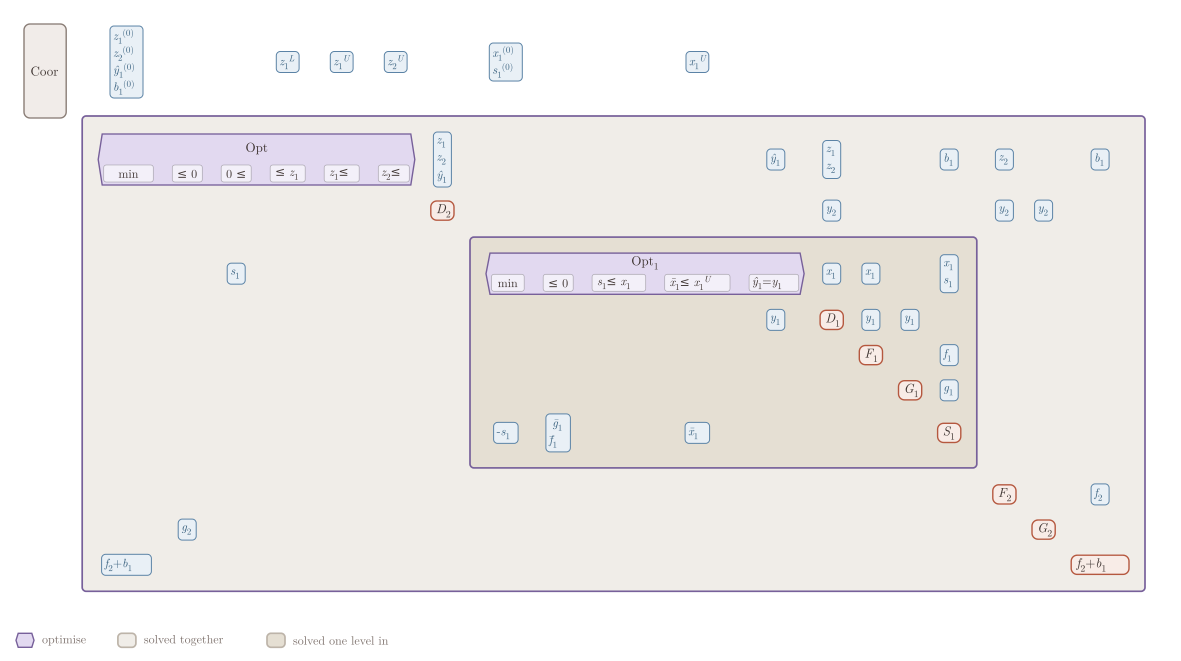

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       9.5e-06   -2.1e-04    6.1e-09    7.9e-04    6.6e-12   -2.1e-04
within 0.001


In [8]:
from distributed_architectures import qsd
model = qsd(base)
display(SVG(RUNS['QSD'].xdsm(model)))
solve('QSD', model)

### BLISS-2000 (Martins & Lambe Eqs. 16–17, Fig. 12)

In BLISS-2000 each subproblem minimises a weighted sum of its outputs, the weights being variables of the system subproblem, and the system subproblem works with surrogate models of the subproblems' optima. Martins & Lambe call it equivalent to the original problem only "provided the weighting coefficients accurately capture the influence of the coupling variables on the objective".

**This is not the published method.** The plan solves the subproblems exactly instead of through surrogates. $D_2$ has no local design variable and so no subproblem: it is evaluated at the system subproblem, which also holds $g_2$.

It reaches Sellar's optimum, but that owes something to Sellar. With a linear objective $w_1 y_1$ the subproblem's answer lies on a vertex of its feasible region, and at Sellar's optimum $x_1 = 0$ is on its bound and $g_1$ is active, which is such a vertex.

**Variables it adds.** $\hat y_i$, the system subproblem\'s targets; $w_1$, the weight on $y_1$; $w_1 y_1$, the subproblem\'s objective.

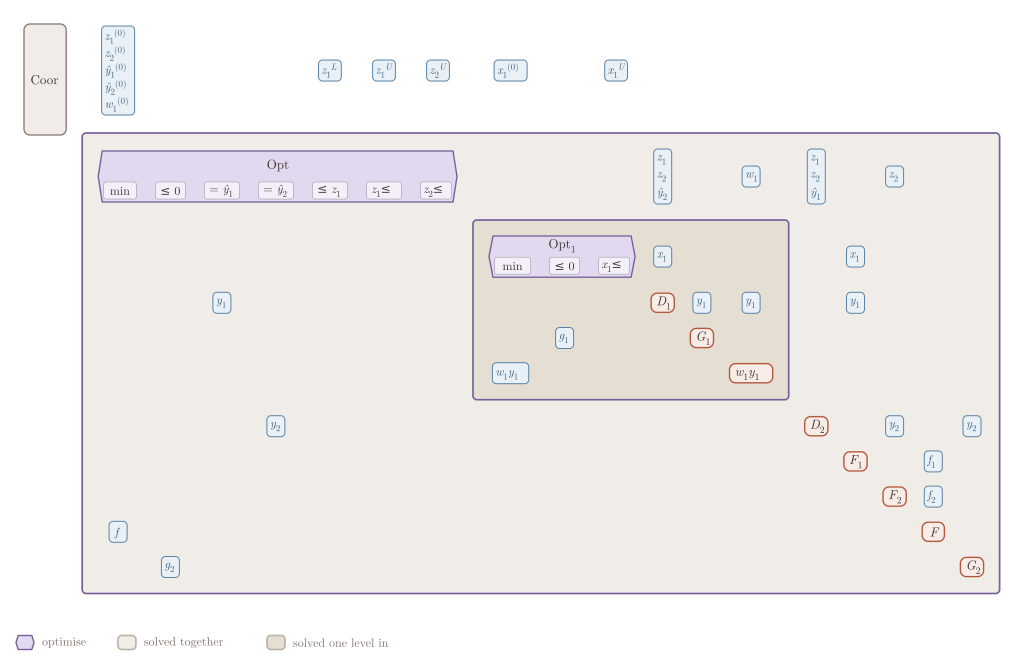

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       4.1e-06   -8.3e-06    7.0e-13    2.7e-05    0.0e+00   -9.4e-06
within 0.001


In [9]:
from distributed_architectures import bliss2000
model = bliss2000(base)
display(SVG(RUNS['BLISS-2000'].xdsm(model)))
solve('BLISS-2000', model)

## Distributed IDF: penalty

### ATC (Martins & Lambe Eqs. 18–19, Fig. 13)

In analytical target cascading the system subproblem and the subproblems each relax the consistency constraints by a penalty on their inconsistency with the others. They are solved in turn until they agree (Martins & Lambe's Algorithm 7), and an outer loop raises the penalty weight until the inconsistency is small. Sellar has no shared objective term $f_0$ and no shared constraints $c_0$, so the system subproblem minimises only its penalty, and there is no penalty $\Phi_0$ on shared constraints.

In cottax the iteration over the problems is a fixed-point problem, $\mathrm{FP}$. It owns copies of whatever the subproblems read from the system subproblem, and holds each copy equal to the system subproblem's value. The system subproblem and the subproblems are nested inside it, and Picard iteration solves them in turn. As in Martins & Lambe's figure, the system subproblem treats the subproblems' copies and responses as fixed, so it evaluates no discipline itself.

The outer loop raises the weight $w$ tenfold per stage from 1 to $10^4$, and each stage starts from the answer of the previous one. Within a stage the iteration is converged before the weight is raised, where Algorithm 7 raises it after each pass; Martins & Lambe note that the subproblems are usually solved "to reasonable accuracy before the penalty weights are updated". The loop runs in the notebook rather than in the graph, because a nested solve cannot yet start from its previous answer, so $w$ enters the graph from Coor. Both alternatives fail: a fixed weight of 100 from the cold start does not converge, and a fixed weight of 1 converges with an error of 0.47.

**Variables it adds.** $\hat z_k^{(i)}$ and $\hat y_i$ as in CO; $w$, the penalty weight; $\Phi_i$, the penalty of subproblem $i$, and $f_i + \Phi_i$, its objective, both computed by the node $\Phi_i$; $\Sigma\Phi$, the system subproblem\'s penalty over every consistency; and $z_k^\prime$ and $\hat y_i^\prime$, the fixed point\'s copies of what the subproblems read from the system subproblem.

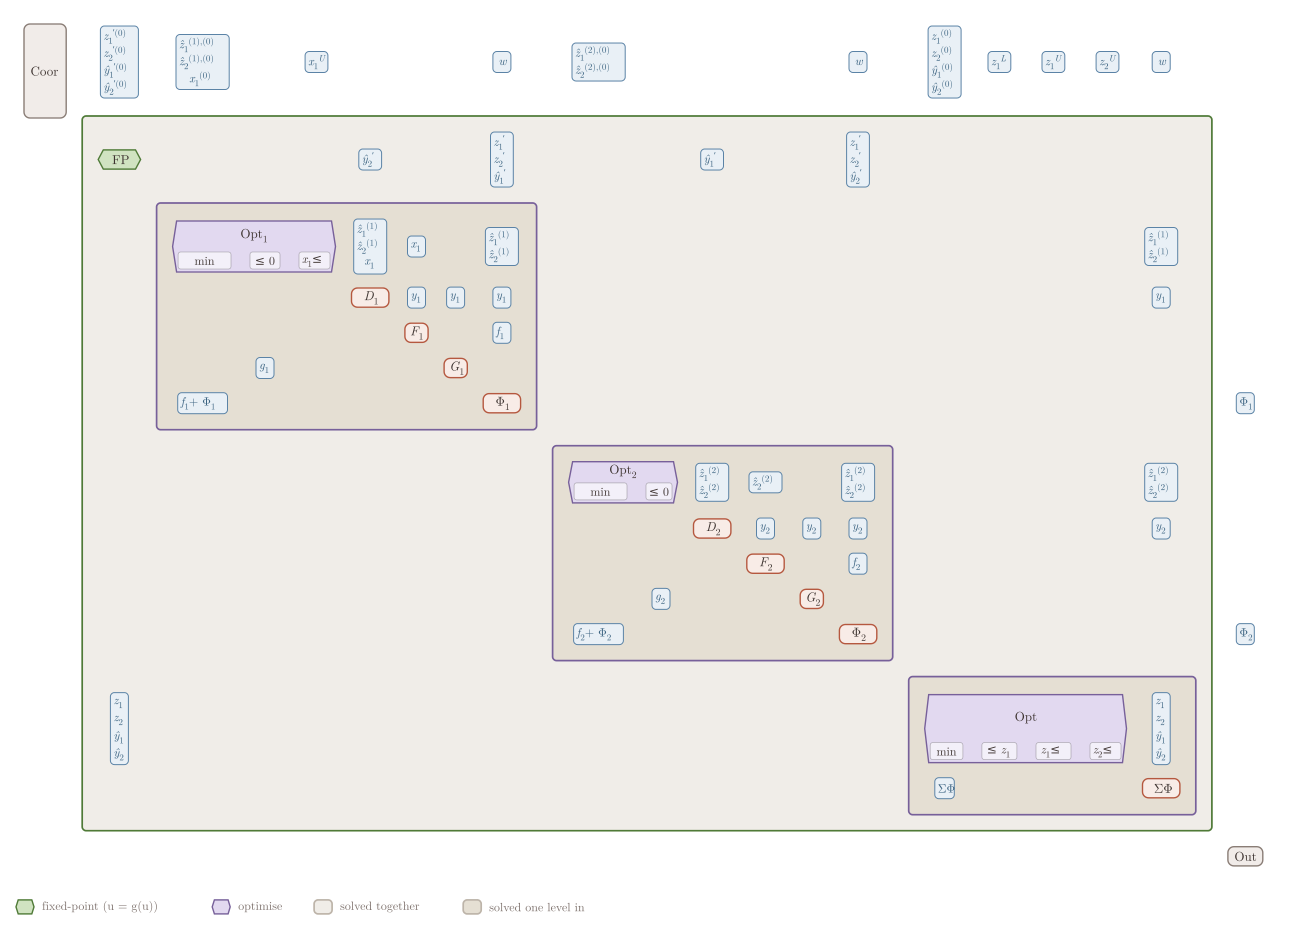

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error      -4.4e-05   -2.3e-06    2.8e-16    0.0e+00    1.4e-10   -5.1e-05
within 0.001


In [10]:
from distributed_architectures import atc
model = atc(base)
display(SVG(RUNS['ATC'].xdsm(model)))
solve('ATC', model)

### IPD (Martins & Lambe Eqs. 20–21, Fig. 14)

In inexact penalty decomposition, each subproblem minimises its own objective term plus a quadratic penalty on its inconsistency with the system subproblem. The system subproblem minimises the sum of the subproblems' optimal penalties, and an outer loop raises the penalty weight. Unlike ATC, the subproblems are nested inside the system subproblem. Tosserams et al. (2009) classify DeMiguel and Murray's penalty decomposition with the nested formulations, as Eq. 21 states it; only the step numbers of Martins & Lambe's Algorithm 8 and Fig. 14 read as if the two levels were solved in turn. The method applies only to problems without a shared objective term $f_0$ and without shared constraints $c_0$, so that the system subproblem is an unconstrained minimisation.

Sellar has neither: its constraints each belong to one discipline, and its objective splits into the terms $f_1$ and $f_2$. The system subproblem holds only the bounds of its own variables $z$. Discipline 2's subproblem owns only its copies of $z_1$ and $z_2$.

The outer loop (Martins & Lambe's Algorithm 8) raises the weight tenfold per stage from 1 to $10^4$, each stage starting from the previous answer, and runs in the notebook as for ATC. Both alternatives fail here too: a fixed weight of 100 from the cold start does not converge, and a fixed weight of 1 converges with an error of 0.33.

At the last weight the system subproblem's objective is about $10^{-4}$. Its convergence tolerance then leaves $z_1$ off by about $10^{-3}$ and $x_1$ by $4 \times 10^{-3}$, and a tighter tolerance makes its line search fail on the noise of the finite differences, so IPD is compared within $5 \times 10^{-3}$.

**Variables it adds.** $\hat z_k^{(i)}$, $\hat y_i$, $w$, $\Phi_i = w\,J_i$ and $f_i + \Phi_i$ as in ATC; $\Sigma\Phi = \Phi_1^* + \Phi_2^*$, the system subproblem\'s objective, the sum of the subproblems\' optimal penalties.

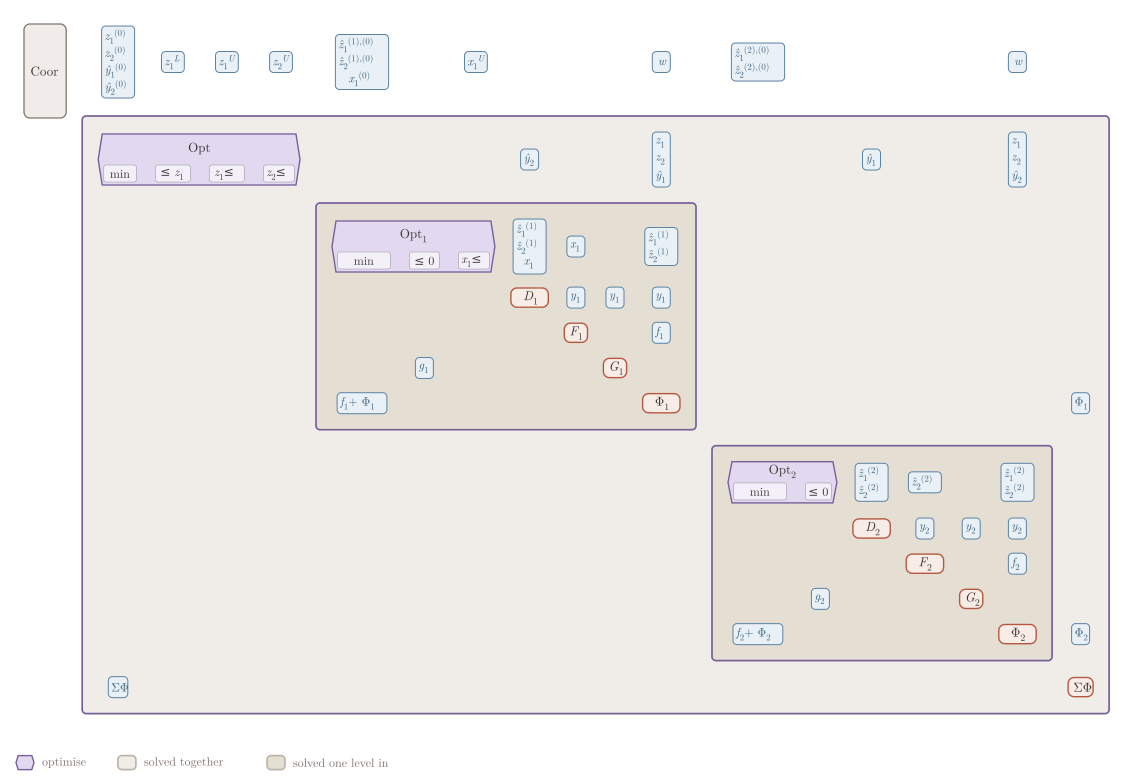

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       1.0e-05   -1.0e-03    0.0e+00    3.9e-03    0.0e+00   -1.0e-03
within 0.005


In [11]:
from distributed_architectures import ipd
model = ipd(base)
display(SVG(RUNS['IPD'].xdsm(model)))
solve('IPD', model)

### EPD (Martins & Lambe Eqs. 20–21, Fig. 14)

Exact penalty decomposition replaces the quadratic penalty by an $L_1$ penalty. Each consistency is written as the difference of two non-negative elastic variables, which keeps the subproblem smooth. With a weight above the largest Lagrange multiplier of the consistency constraints the penalty is exact, and the outer loop instead lowers a logarithmic barrier on the elastic variables, as in an interior-point method.

Here the weight is fixed at 10, assumed rather than shown to exceed the multipliers, and the barrier is lowered tenfold per stage from 1 to $10^{-6}$. Without the barrier the system subproblem's objective is piecewise linear in its variables, and it stalls at a kink.

EPD does not yet run. DeMiguel & Murray solve its subproblems with an interior-point method, while SLSQP is an active-set method. On the barrier, SLSQP stops at its iteration limit or finds its linearised constraints incompatible, even near the optimum. Running EPD needs an interior-point solver, which cottax does not wrap yet.

**Variables it adds.** Those of IPD, and in addition $p_{i,k}, n_{i,k} \ge 0$, the positive and negative elastic parts of consistency $k$ of subproblem $i$; $r_{i,k}$, that consistency minus $p_{i,k} - n_{i,k}$, held at zero; and $\mu$, the barrier parameter.

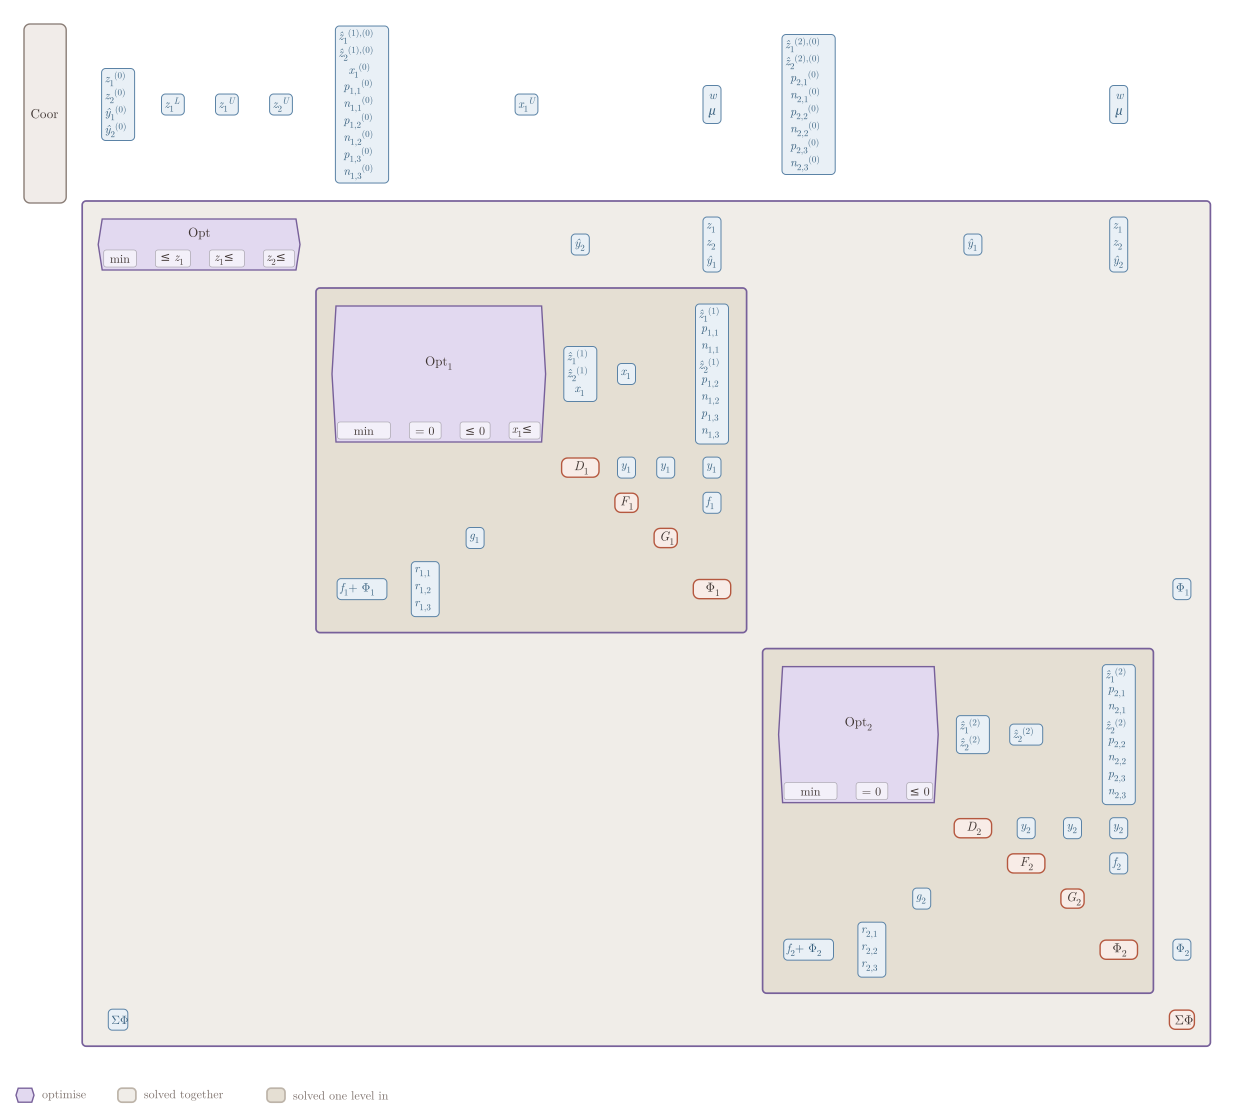

jax.pure_callback failed
Traceback (most recent call last):
  File "/home/wrutten/anaconda3/envs/func_PROCESS_env/lib/python3.14/site-packages/jax/_src/callback.py", line 93, in pure_callback_impl
    return tree_util.tree_map(np.asarray, callback(*args))
                                          ~~~~~~~~^^^^^^^
  File "/home/wrutten/anaconda3/envs/func_PROCESS_env/lib/python3.14/site-packages/jax/_src/callback.py", line 71, in __call__
    return tree_util.tree_leaves(self.callback_func(*args, **kwargs))
                                 ~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^
  File "/home/wrutten/projects/jaxgraph/src/cottax/relational/consumers/execution/jax_solvers/scipy_slsqp.py", line 181, in _minimise
    raise RuntimeError(f'SLSQP did not converge: {result.message}')
RuntimeError: SLSQP did not converge: Iteration limit reached


failed: SLSQP did not converge: Iteration limit reached


In [12]:
from distributed_architectures import epd
model = epd(base)
display(SVG(RUNS['EPD'].xdsm(model)))
solve('EPD', model)

## Distributed MDF

### ASO (Martins & Lambe Eqs. 25–26, Fig. 17)

Asymmetric subspace optimisation keeps MDF's structure but optimises one discipline inside the MDA. That discipline's local variables are chosen afresh at every MDA iteration, while the system subproblem handles the rest. The method suits a cheap discipline coupled to an expensive one.

Only $D_1$ has a local design variable, so $D_1$ is optimised and $D_2$ is only analysed in the MDA. The MDA owns the copy $\hat y_1$, which $D_2$ reads, so each MDA iteration runs $D_2$ and then the subproblem, as in Martins & Lambe's Algorithm 11. The subproblem reads $y_2$ as fixed, so each of its iterations re-runs $D_1$ alone.

From the standard start, the system subproblem, which sees only $z$, overshoots into negative $z_1$. It converges there to Sellar's other local minimum, $f = 4.131$ at $z = (-1.717,\, 0.138)$, where MDF also stays when started there. From $z = (3, 1)$ or closer it reaches the global optimum. The start is the same for every plan and has not been changed.

**Variables it adds.** $\hat y_1$, the copy of $y_1$ that the MDA iterates on.

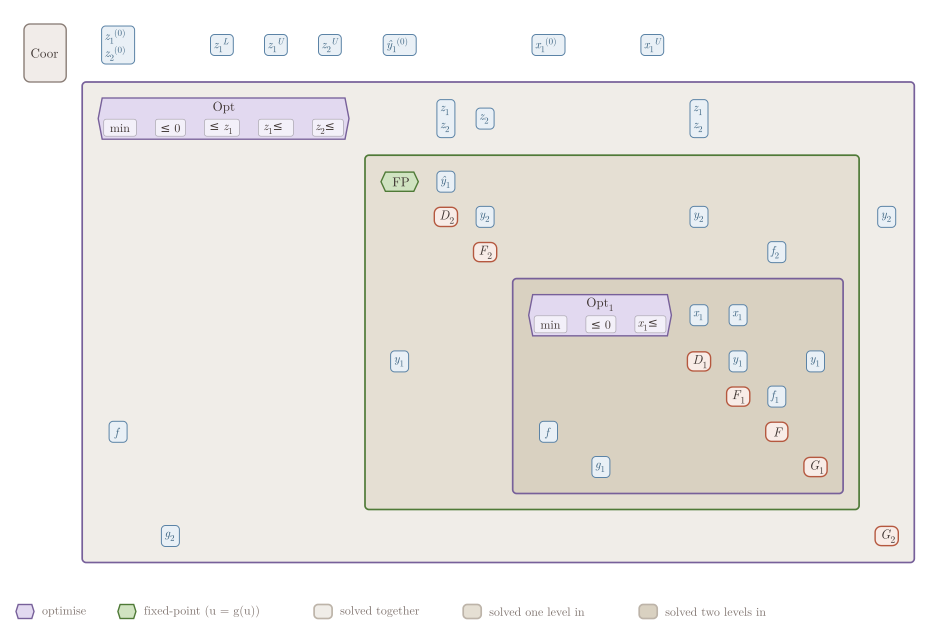

                  f         z1         z2         x1         y1         y2
optimum     3.18339    1.97764    0.00000    0.00000    3.16000    3.75528
error       9.5e-01   -3.7e+00    1.4e-01    1.1e-01   -8.9e-16   -3.6e+00
off by 3.7e+00 (tolerance 0.001)


In [13]:
from distributed_architectures import aso
model = aso(base)
display(SVG(RUNS['ASO'].xdsm(model)))
solve('ASO', model)

### MDOIS (Martins & Lambe Eq. 22, Fig. 15)

MDO of independent subspaces applies only to problems without shared design variables, shared objective terms or shared constraints. Sellar shares $z_1$ and $z_2$ between both disciplines, so there is no MDOIS plan for it.

### Not built: CSSO, BLISS and ECO

Concurrent subspace optimisation (Eqs. 7–8), BLISS (Eqs. 14–15) and enhanced collaborative optimisation (Eqs. 11–13) each solve their subproblems on approximations: CSSO on surrogate models of the other disciplines, fitted to a design of experiments; BLISS on linearisations built from coupled and post-optimality derivatives; ECO on quadratic and linear models of the objective and of the other disciplines' constraints. The derivatives and surrogates can be written as function nodes in the graph, although not efficiently. A design of experiments needs a driver cottax does not have yet, so these three wait for it.

## Overview

The table collects the outcome of every architecture above: whether it reached the optimum within its tolerance, the largest error over $f$, $z_1$, $z_2$, $x_1$, $y_1$ and $y_2$, and the error in $f$. The reason for each tolerance is given in that architecture's section.

In [14]:
display(Markdown(overview(results)))

| architecture | result | largest error | error in `f` | tolerance | note |
|---|---|---|---|---|---|
| AAO | within tolerance | 4.0e-06 | +4.0e-06 | 0.0001 |  |
| SAND | within tolerance | 4.0e-06 | +4.0e-06 | 0.0001 |  |
| IDF | within tolerance | 4.0e-06 | +4.0e-06 | 0.0001 |  |
| MDF | within tolerance | 4.0e-06 | +4.0e-06 | 0.0001 |  |
| CO1 | failed: SLSQP did not converge: More equality constraints than independent variables | | | |  |
| CO2 | within tolerance | 1.0e-03 | +5.7e-06 | 0.002 |  |
| QSD | within tolerance | 7.9e-04 | +9.5e-06 | 0.001 | system subproblem stopped at its iteration limit |
| BLISS-2000 | within tolerance | 2.7e-05 | +4.1e-06 | 0.001 | subproblems solved exactly, without surrogates |
| ATC | within tolerance | 5.1e-05 | -4.4e-05 | 0.001 |  |
| IPD | within tolerance | 3.9e-03 | +1.0e-05 | 0.005 |  |
| EPD | failed: SLSQP did not converge: Iteration limit reached | | | |  |
| ASO | the other local minimum, f = 4.131 | 3.7e+00 | +9.5e-01 | 0.001 |  |

Every monolithic architecture and most of the distributed ones reach the same optimum from the same declared problem. Those that do not fall short for reasons outside the plan's structure:

- CO1 fails as Martins & Lambe predict, because its system subproblem has more equality constraints than unknowns.
- EPD needs an interior-point solver for its barrier.
- ASO converges correctly, but to Sellar's other local minimum.

QSD's answer is taken at its iteration limit, and BLISS-2000 is built without its surrogates. In every case the architecture was built from the same few graph operations, applied to one declaration that names no architecture.

## References

- Martins, J. R. R. A. and Lambe, A. B. (2013). Multidisciplinary design optimization: a survey of architectures. *AIAA Journal* 51(9), 2049–2075.
- Sellar, R. S., Batill, S. M. and Renaud, J. E. (1996). Response surface based, concurrent subspace optimization for multidisciplinary system design. AIAA paper 96-0714.
- Gray, J., Moore, K. T., Hearn, T. A. and Naylor, B. A. (2013). Standard platform for benchmarking multidisciplinary design analysis and optimization architectures. *AIAA Journal* 51(10), 2380–2394.
- DeMiguel, V. and Murray, W. (2006). A local convergence analysis of bilevel decomposition algorithms. *Optimization and Engineering* 7(2), 99–133.
- Tosserams, S., Etman, L. F. P. and Rooda, J. E. (2009). A classification of methods for distributed system optimization based on formulation structure. *Structural and Multidisciplinary Optimization* 39(5), 503–517.